<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Time Series II: Modeling

_Author: Tim Book_

---

### Learning Objectives
By the end of this lesson, students should be able to: 
- Understand the Classical decomposition of a time series
- Describe the components of the ARIMA model and their significance

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV

import statsmodels.api as sm
import itertools

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox


# Comparing Additive and Multiplicative Decomposition on J & J

As a quick example, we'll decompose the J&J earnings two ways, additive and multiplicative, and compare what's left over...

Additive seasonal components: [0.222, 0.244, 0.309, -0.774]
Multiplicative seasonal components: [0.993, 1.033, 1.114, 0.86]
Additive STL seasonal components: [0.016, -0.006, 0.207, -0.207]
Multiplicative STL seasonal components: [1.051, 1.019, 1.358, 0.705]


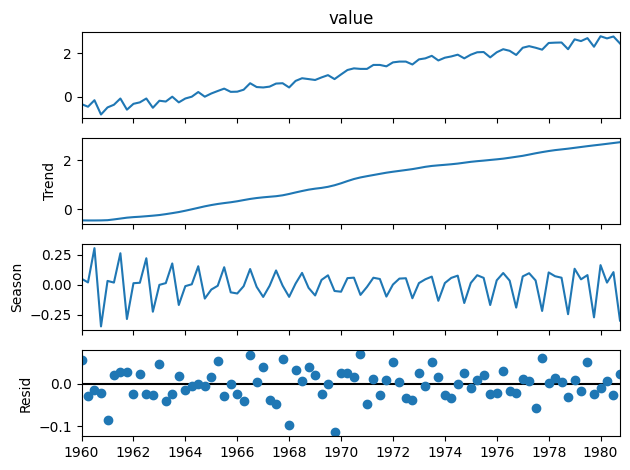

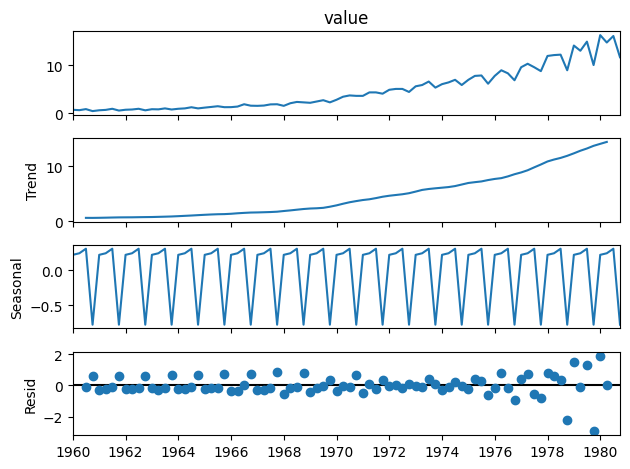

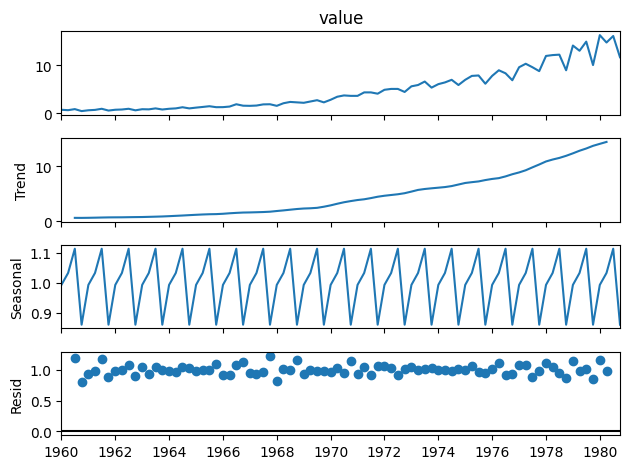

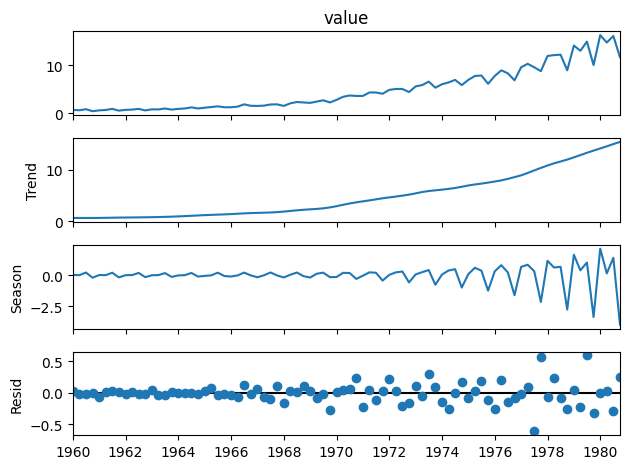

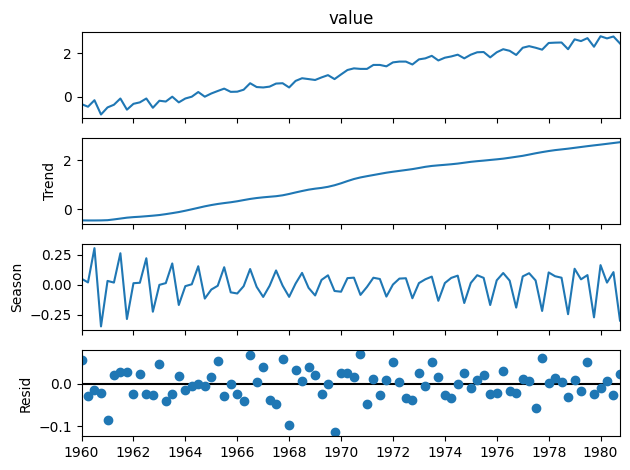

In [44]:
jj = sm.datasets.get_rdataset('JohnsonJohnson').data
jj.index = pd.period_range('1960Q1', periods=len(jj), freq='Q').to_timestamp()
y = jj['value']   # quarterly earnings per share

additive = seasonal_decompose(y, model='additive', period=4)
multiplicative = seasonal_decompose(y, model='multiplicative', period=4)


print(f"Additive seasonal components: {additive.seasonal[:4].round(3).tolist()}")                    # [0.222, 0.244, 0.309, -0.774]: amounts added
print(f"Multiplicative seasonal components: {multiplicative.seasonal[:4].round(3).tolist()}")        # [0.993, 1.033, 1.114, 0.86]: factors multiplied

# compare the residual panels
additive.plot();   
multiplicative.plot();




# Better alternative STL
stl_additive = STL(y, period=4).fit()

# Multiplicative STL (via log-transform)
log_y = np.log(y)
stl_multiplicative_log = STL(log_y, period=4).fit()

additive_seasonal = stl_additive.seasonal
multiplicative_seasonal = np.exp(stl_multiplicative_log.seasonal)

print(f"Additive STL seasonal components: {additive_seasonal[:4].round(3).tolist()}")
print(f"Multiplicative STL seasonal components: {multiplicative_seasonal[:4].round(3).tolist()}")

stl_additive.plot()
stl_multiplicative_log.plot()

**Which version leaves residuals that look more like random noise?**

* The ***additive residuals*** fan out over time, so *(the model is wrong for growing swings)*
* The ***multiplicative residuals*** are much more even.

That motivates the transforms used later in the ARIMA example

# Other Examples

Today's second example dataset will be the average air temperature (F) recorded at Nottingham Castle recorded monthly from 1920 to 1939

In [3]:
# when reading in the data, we want to make sure that the date column is parsed as a datetime object and set as the index of the DataFrame.
# This is important for time series analysis, as it allows us to easily manipulate and visualize the data based on time.
# we will specify a format for the date as well, which will help pandas correctly interpret the date strings in the CSV file.
# nottem = pd.read_csv('../data/nottingham.csv', parse_dates=['date'], index_col='date', date_format='%m-%Y')
# nottem = pd.read_csv('../data/nottingham.csv', parse_dates=['date'], index_col='date')

nottem = pd.read_csv('../data/nottingham.csv', date_format='%m-%Y')
nottem.date = pd.to_datetime(nottem.date)
nottem.set_index('date', inplace=True)
nottem.head()

C:\Users\CharleyHanania\AppData\Local\Temp\ipykernel_45240\2656797782.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  nottem.date = pd.to_datetime(nottem.date)


,temp
date,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


In [4]:
nottem.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 1920-01-01 to 1939-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB


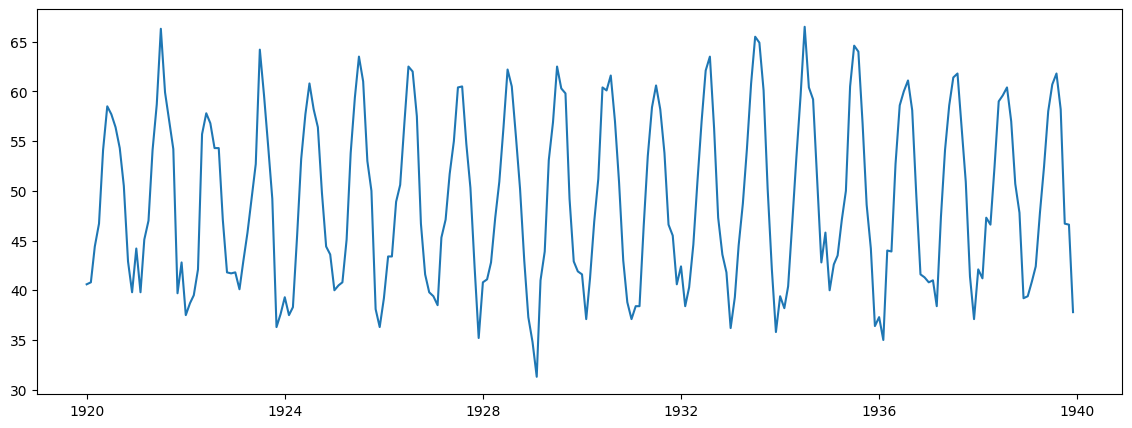

In [5]:
plt.figure(figsize=(14, 5))
plt.plot(nottem);

**(THREAD):** Describe this time series. Is it stationary? Is there seasonality?

Check out the ACF plot, PACF plot, and the `statsmodels` decomposition below. Does this validate your opinions?

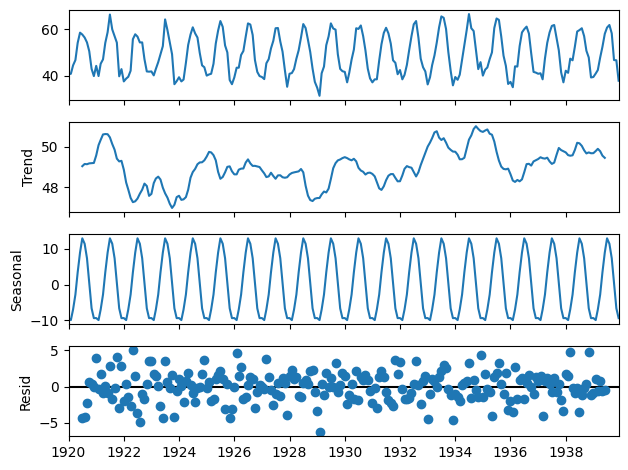

In [6]:
# Decomposition
# Seasonality graph seems strong, the trend seems flat-ish, and the
# noise graph is totally random.

decomp = seasonal_decompose(nottem)
decomp.plot();

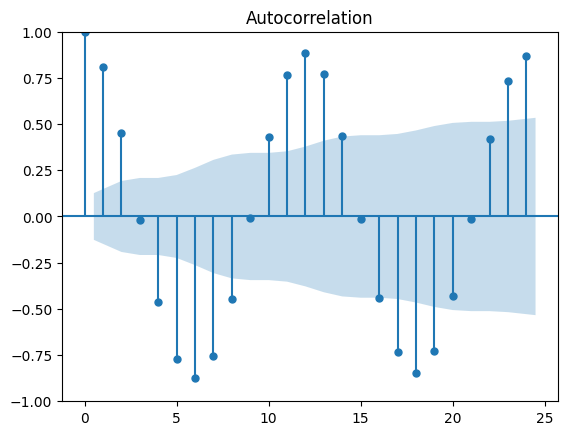

In [7]:
# ACF
# We see strong autocorrelations at 6, 12, 18, 24, etc
plot_acf(nottem);

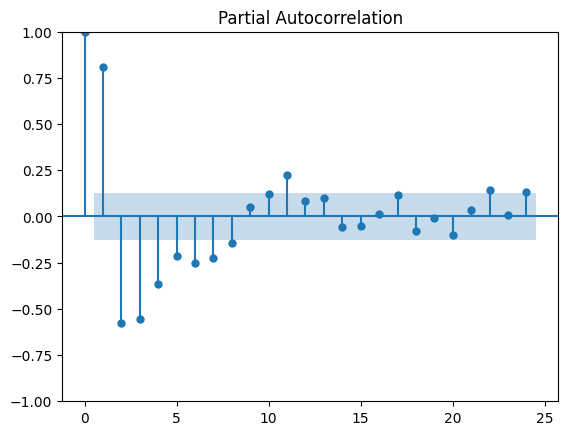

In [8]:
# PACF is the partial autocorrelation function, which measures the 
# correlation between a time series and its lagged values, controlling 
# for the values of the time series at all shorter lags.
# When compared to ACF, PACF can help identify the order of an autoregressive (AR) model.
# Order meaning, how many lagged values of the time series should be included as predictors in the model.

# We see the same thing as in ACF but a little weaker
# this is because in this case PACF is showing the correlation
# of the series with its own lagged values, controlling for the
# values of the time series at all shorter lags.

# Most significantly notice that for the first 6 lags, the PACF 
# is significant, but after that, it drops off to near zero. 
# This suggests that an AR model of order 6 might be appropriate for this data.
plot_pacf(nottem);

**Back to the Slides!**

# Model Prep

In [9]:
# Do a train-test split holding out only 10% of our data unshuffled (why?)

# This is because time series data is sequential, and shuffling would destroy
# the temporal structure of the data. By keeping the last 10% of the data as
# a test set, we can evaluate how well our model performs on future unseen data.
nottem['month'] = nottem.index.month
y_train, y_test = train_test_split(nottem, test_size=0.1, shuffle=False, random_state=123)

y_train.shape, y_test.shape

((216, 2), (24, 2))

# Create components
- $m_t$ : We'll assume no trend here and just let $\hat m_t = \bar y$
- $s_t$ : Since we have monthly data we'll just let $\hat s_t$ be the mean temperature per month with the trend removed.

In [10]:
# Here we are calculating the mean temperature for the training set,
# which will be used to calculate the seasonal component of the time series.
# The seasonal component is calculated by subtracting the overall mean
# temperature from the mean temperature for each month.
# This helps us understand how much the temperature deviates from the
# average for each month, which is important for modeling and forecasting.
mt = y_train.temp.mean()
print(f"Mean temperature for training set: {mt:.2f}")

# Next we calculate the seasonal component (st) of the time series by grouping
# the training data by month and calculating the mean temperature for each month.
# We then subtract the overall mean temperature from each month's mean temperature to get the seasonal component.
y_train.groupby('month', as_index=False).temp.mean()
st = y_train.groupby('month', as_index=False).temp.mean()
st['seasonal'] = st.temp - mt

print(f"\nSeasonal component for each month:")
st.round(2)
# st[['month','temp','seasonal']].round(2)

Mean temperature for training set: 48.95

Seasonal component for each month:


,month,temp,seasonal
0,1,39.58,-9.37
1,2,38.98,-9.97
2,3,41.90,-7.05
3,4,46.19,-2.76
4,5,52.58,3.63
5,6,57.99,9.04
6,7,62.09,13.14
7,8,60.46,11.50
8,9,56.36,7.40
9,10,49.58,0.63


# Predictions
This might not _feel_ like a model, but we actually have enough to make basic predictions now.

Let's merge the seasonal components back onto the testing data and add the trend back on. Those are our predictions!

In [11]:
# first, we need to merge the seasonal component back into
# the test set so that we can make predictions for the test set.
# how=left means that we want to keep all the rows from the left dataframe (y_test)
y_test_pred = y_test.merge(st[['month', 'seasonal']], how='left')

# then, we can add the mean temperature to the seasonal component
# to get our final predictions.
y_test_pred['y_pred'] = mt + y_test_pred['seasonal']

# We now have our predictions for the test set, but we need to
# make sure that the index of our predictions matches the index
# of the test set. 
# This is important because we want to be able to compare our
# predictions to the actual values in the test set.
y_test_pred.index = y_test.index
y_test_pred

,temp,month,seasonal,y_pred
date,,,,
1938-01-01,42.1,1,-9.373611,39.577778
1938-02-01,41.2,2,-9.968056,38.983333
1938-03-01,47.3,3,-7.051389,41.900000
1938-04-01,46.6,4,-2.762500,46.188889
1938-05-01,52.4,5,3.626389,52.577778
1938-06-01,59.0,6,9.037500,57.988889
1938-07-01,59.6,7,13.143056,62.094444
1938-08-01,60.4,8,11.504167,60.455556
1938-09-01,57.0,9,7.404167,56.355556


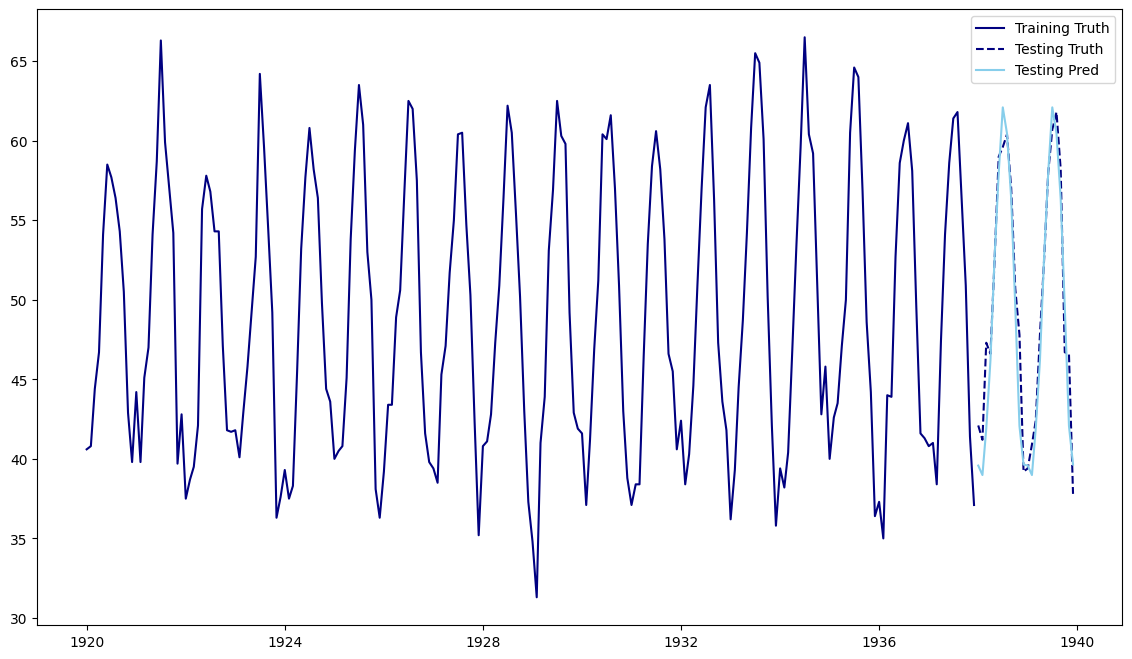

In [12]:
# Pretty good!
plt.figure(figsize=(14, 8))
plt.plot(y_train.temp, c='navy', label='Training Truth')
plt.plot(y_test_pred.temp, c='navy', linestyle='--', label='Testing Truth')
plt.plot(y_test_pred.y_pred, c='skyblue', label='Testing Pred')

plt.legend();

# ARIMA with Airline Data
Our third dataset is monthly airline data from Box and Jenkins (1976).

In [13]:
air = pd.read_csv('../data/airline-passengers.csv', parse_dates=['Month'], index_col='Month', date_format='%Y-%m')
# air.Month = pd.to_datetime(air.Month)
# air.set_index('Month', inplace=True)
air.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


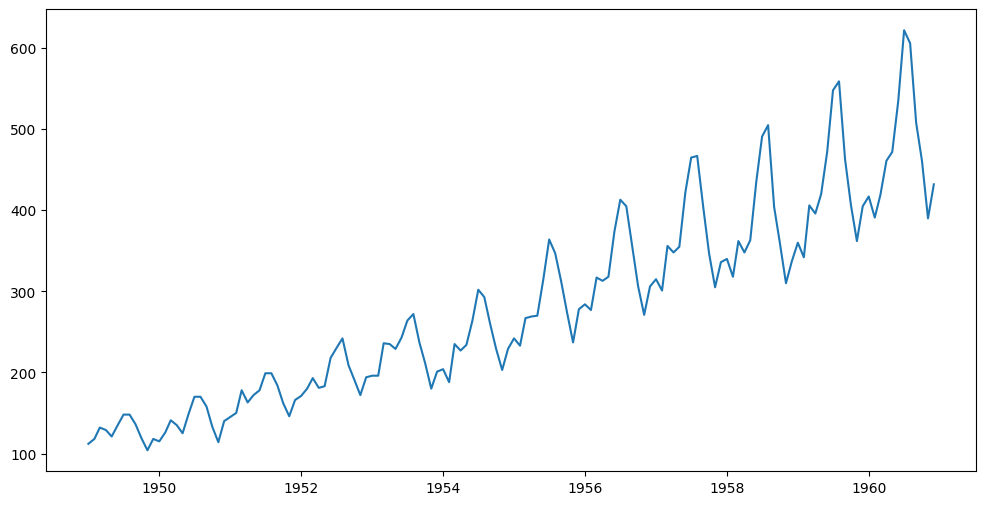

In [14]:
plt.figure(figsize=(12, 6))
plt.plot(air);

**(THREAD):** Let's set aside the last 24 rows (two years) as testing data _without using the_ `train_test_split()` function!

In [15]:
# Someone please explain this notation :)
h = 24
y_train = air.iloc[:-h]
y_test  = air.iloc[-h:]

In [16]:
y_train.shape, y_test.shape

((120, 1), (24, 1))

## Stationarity with the ADF Test

Let's do some EDA to see how many diffs it takes to achieve stationarity. We'll also do an **Augmented Dickey-Fuller test** to be "official" about it.

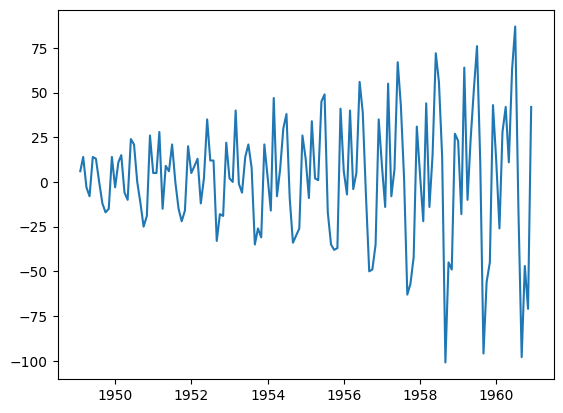

In [17]:
# Once is probably fine
plt.plot(air.diff());


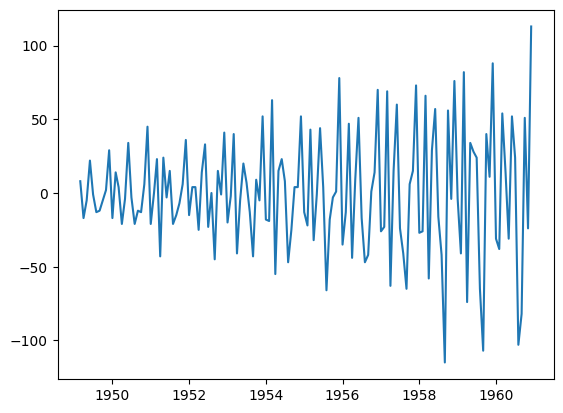

In [18]:
# Twice doesn't change much
# Why twice? Because the first difference removes the trend, 
# and the second difference removes any remaining seasonality. 
# This is a common technique in time series analysis to make 
# the data stationary, which is often a requirement for many modeling techniques.
plt.plot(air.diff().diff())

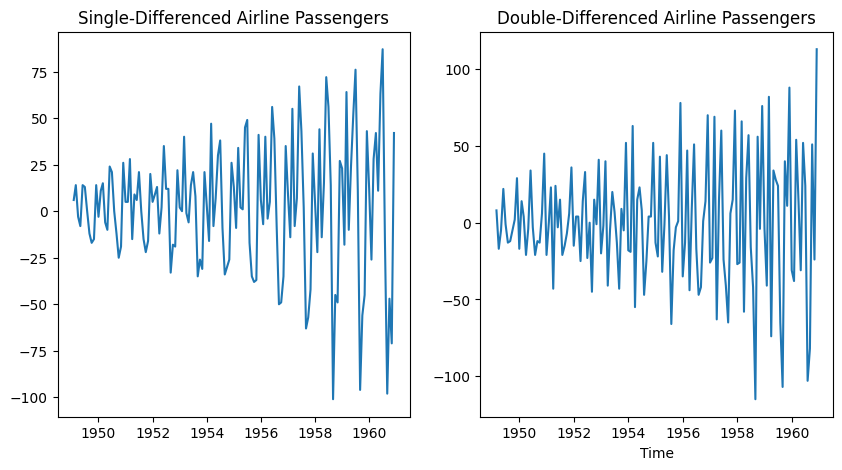

In [19]:
# We described previously that in a real machine learning pipeline, we don't actually need a distinct test for every scenario because the remedies to fix non-stationarity are very straightforward:
#1. If it fails the ADF (Has a Trend): Apply First-Order Differencing (df.diff()). This subtracts yesterday's value from today's value, flattening out the trend line.
#2. If it fails the KPSS (Has Seasonality): Apply Seasonal Differencing (df.diff(periods=12)). This subtracts last year's value from this year's value to strip out cyclical waves.
#3. If it has Changing Variance (Megaphone shape): Apply a Log Transform (np.log(df)) or a Box-Cox transformation. This compresses the large swings down to a uniform scale.

air_diff  = air.diff()
air_ddiff = air.diff().diff()

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)

plt.plot(air_diff)
plt.title('Single-Differenced Airline Passengers')

plt.subplot(1,2,2)
plt.plot(air_ddiff)
plt.title('Double-Differenced Airline Passengers')

plt.xlabel('Time')
plt.show()



## The **Augmented** Dickey Fuller test
The technicalities are outside our scope, but you can read more about it [here](https://en.wikipedia.org/wiki/Augmented_Dickey%E2%80%93Fuller_test).

In short, we're testing:

$$
H_0: \text{time series not stationary} \\
H_A: \text{time series stationary}
$$

The result is a **p-value**

**Decision Rules for the p-value**

* p-value ≤ significance level (e.g., < 0.05):
	- **Decision:** *Reject* the null hypothesis (H₀).
	- **Conclusion:** The data is stationary. It has a stable mean, variance, and autocovariance over time, making it safe for models like ARIMA.
* p-value > significance level (e.g., ≥ 0.05):
	- **Decision:** *Fail to reject* the null hypothesis (H₀).
	- **Conclusion:** The data is non-stationary (or has a unit root/trend). We need to apply transformations like differencing before further modeling.

In [20]:
adf_diff1, pval_diff1, *_ = adfuller(air.diff().dropna(), result_object=True)
adf_diff2, pval_diff2, *_ = adfuller(air.diff().diff().dropna(), result_object=True)

print(f"diff'd once  p-value = {pval_diff1:.40f}\ndiff'd twice p-value = {pval_diff2:.40f}\n")
# Looks like we may have to diff twice to be stationary!

if (pval_diff1 <= 0.05):
    print(f"ADF Test: the Single-Differenced Airline Passengers data is Stationary!")
else:
    print(f"ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!")


if (pval_diff2 <= 0.05):
    print(f"ADF Test: the Double-Differenced Airline Passengers data is Stationary!")
else:
    print(f"ADF Test: the Double-Differenced Airline Passengers data is non-Stationary!")


diff'd once  p-value = 0.0542132902838262098477173367427894845605
diff'd twice p-value = 0.0000000000000000000000000000273289185001

ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!
ADF Test: the Double-Differenced Airline Passengers data is Stationary!


## First Attempt: ARIMA(1, 2, 1)

Let's use `statsmodels` to fit an ARIMA(1, 2, 1) model.

In [21]:
model = ARIMA(y_train, order=(1, 2, 1)).fit()

# Why 1,2,1? Just to show the effect of differencing twice (d=2) and using a simple ARMA model (p=1, q=1).
# We'll be using a more systematic approach to determine the best parameters for our ARIMA model in the next sections,
# but for now, this serves as a simple example of how differencing can help us achieve stationarity in our time series data.

C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [22]:
model.summary()
# This summary shows the results of fitting an ARIMA
# model to the training data. The order (1, 2, 1)
# indicates that we are using one autoregressive term,
# two differences to make the series stationary, and
# one moving average term. The summary provides information
# about the coefficients of the model, their statistical
# significance, and various diagnostic statistics that
# can help assess the model's fit to the data.

# in this case, we see that the coefficients for the
# AR and MA terms are statistically significant, as
# indicated by their low p-values. The AIC and BIC
# values can be used to compare this model to other
# models with different orders, with lower values
# indicating a better fit.
# Overall, this summary
# provides valuable information for evaluating
# the performance of the ARIMA model on the training data.

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  120
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -560.986
Date:                Sun, 25 Oct 2026   AIC                           1127.973
Time:                        23:00:25   BIC                           1136.285
Sample:                    01-01-1949   HQIC                          1131.348
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2938      0.110      2.665      0.008       0.078       0.510
ma.L1         -0.9998      6.157     -0.162      0.871     -13.067      11.067
sigma2       761.4552   4718.370      0.161      0.872   -8486.380       1e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.38   Jarque-Bera (JB):                 5.62
Prob(Q):                              0.54   Prob(JB):                         0.06
Heteroskedasticity (H):               7.13   Skew:                            -0.07
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.06
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Evaluation

You might notice a lack of $R^2$! The preferred evaluation metric is the [Akaike Information Criterion (AIC)](https://en.wikipedia.org/wiki/Akaike_information_criterion). It won't make sense at first glance - but it's an error metric where lower is better, and it's based off the specific loss function of the ARIMA model.

**TL;DR:** We'll use AIC as our model evaluation of choice. Lower is better!

**NOTE:** Several alternative model selection criteria have been proposed and studied in statistical literature. These include the *Bayesian information criterion (BIC)*, *cross-validation methods*, *least squares fitting*, *Mallows's Cp*, and other information-theoretic approaches such as *Widely Applicable Information Criterion (WAIC)*, *Deviance information criterion (DIC)*, and *Hannan–Quinn information criterion (HQC)*.

These methods differ in their assumptions, asymptotic behavior, and suitability depending on the goals of the analysis — such as prediction, inference, or model interpretation.

In [23]:
model.aic


1127.9726152551664

## "Grid Search"

Since we're using `statsmodels`, we can actually use `GridSearchCV`, but that's ok! We can make our own loop.

In [24]:
from itertools import product

In [25]:
%%time

p_array = np.arange(13)
d = 2
q_array = np.arange(13)

results = []

for p, q in product(p_array, q_array):
    model = ARIMA(y_train, order=(p, d, q)).fit()
    results.append((p, q, model.aic))



C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFounda

CPU times: total: 1min 28s
Wall time: 1min 27s


C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [26]:
df_res = pd.DataFrame(results, columns=['p', 'q', 'aic'])
df_res.sort_values('aic').head(10)

,p,q,aic
146,11,3,921.370389
147,11,4,922.962883
148,11,5,924.893211
144,11,1,925.523729
156,12,0,925.922852
149,11,6,926.735036
145,11,2,927.183305
160,12,4,927.496823
158,12,2,927.519748
159,12,3,927.744616


In [27]:
# Now lets fit the best model and check the summary.
# The best model is the one with the lowest AIC value, which indicates a better fit to the data.
# we'll assign the values to variables for clarity and then fit the model.
best_p, best_q = df_res.sort_values('aic', ascending=True).iloc[0][['p', 'q']]
current_d = 2 # This is the number of differences we applied to the series to make it stationary.
# Differencing twice (d=2) was necessary to achieve stationarity in the airline passengers data.

In [28]:
# Best model summary
model = ARIMA(y_train, order=(best_p, current_d, best_q)).fit();
# The ARIMA parameters supplied map as follows:
# * y_train is the time series data,
# * p=11 is the order of the autoregressive (AR) term,
# * d=2 is the number of differences needed to make the series stationary, and
# * q=3 is the order of the moving average (MA) term.
# This means that the model will use 11 lagged values of the time series as predictors,
# apply two differences to the series to remove trend and seasonality,
# and use 3 lagged forecast errors as predictors in the moving average component.

model.summary()

C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFounda

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  120
Model:                ARIMA(11, 2, 3)   Log Likelihood                -445.685
Date:                Sun, 25 Oct 2026   AIC                            921.370
Time:                        23:01:53   BIC                            962.931
Sample:                    01-01-1949   HQIC                           938.245
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8514      0.112     -7.584      0.000      -1.071      -0.631
ar.L2         -0.9822      0.058    -16.954      0.000      -1.096      -0.869
ar.L3         -0.8439      0.096     -8.830      0.000      -1.031      -0.657
ar.L4         -0.9402      0.057    -16.430      0.000      -1.052      -0.828
ar.L5         -0.8229      0.094     -8.746      0.000      -1.007      -0.639
ar.L6         -0.9276      0.056    -16.678      0.000      -1.037      -0.819
ar.L7         -0.8327      0.094     -8.905      0.000      -1.016      -0.649
ar.L8         -0.9452      0.058    -16.265      0.000      -1.059      -0.831
ar.L9         -0.8650      0.088     -9.871      0.000      -1.037      -0.693
ar.L10        -0.9638      0.039    -24.777      0.000      -1.040      -0.888
ar.L11        -0.8308      0.095     -8.729      0.000      -1.017      -0.644
ma.L1         -0.3596      0.169     -2.125      0.034      -0.691      -0.028
ma.L2          0.2009      0.185      1.083      0.279      -0.163       0.564
ma.L3         -0.3299      0.169     -1.954      0.051      -0.661       0.001
sigma2        96.9203     16.494      5.876      0.000      64.593     129.248
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 9.16
Prob(Q):                              0.95   Prob(JB):                         0.01
Heteroskedasticity (H):               2.75   Skew:                            -0.08
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.36
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

# Predictions and Evaluation

In [29]:
y_test_pred = model.predict(start=y_test.index[0], end=y_test.index[-1])

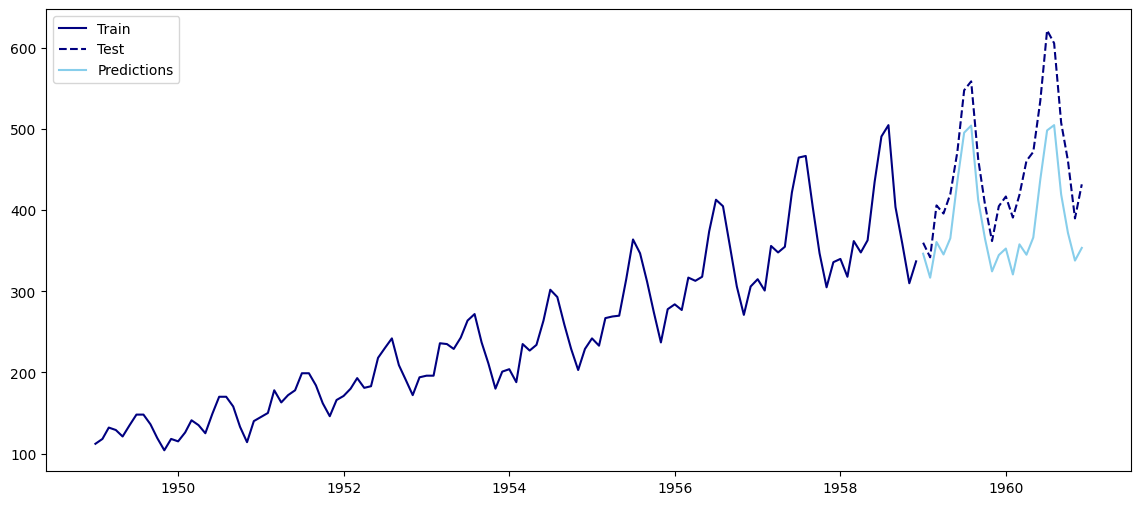

In [30]:
plt.figure(figsize=(14, 6))
plt.plot(y_train, c='navy', label='Train')
plt.plot(y_test, c='navy', linestyle='--', label='Test')
plt.plot(y_test_pred, c='skyblue', label='Predictions')
plt.legend();

There appears to be some series underestimation - this is normal for a model like this that appears to have rising variance over time!

# Conclusions and Takeaways
- You can use simple heuristics rather than ML models to make forecasts on certain scenarios
- The ARIMA model is the base form of models for modeling time series
- There are many variants and additions to the ARIMA model!
- TS modeling works best when the past predicts future. Weather, sales, and deaths - yes! The stock market - no!

# **Bonus Exercise** 🏋️‍♂️🏋️‍♀️ : Full Workflow Review using J&J Example

Let's build an ARIMA model, following the full workflow. 

We'll:
* Split the J&J data in time order
* Build two simple baselines
* Make the series stationary
* Look at the autocorrelation plots
* Ssearch for the best ARIMA settings
* check the residuals are random, and
* finally compare errors on the last two years

**NOTE:** Try to predict the baselines' MAE before running the model!


In [31]:

jj.index = pd.period_range('1960Q1', periods=len(jj), freq='Q').to_timestamp()
y = np.log(jj['value'])              # log tames the growing variance
train, test = y[:-8], y[-8:]         # chronological split: last 2 years held out


In [32]:
# 1. Naive baselines - on the original scale
actual = np.exp(test).values

naive = np.repeat(np.exp(train.iloc[-1]), 8)                  # repeat the last observed value

seasonal_naive = np.tile(np.exp(train.iloc[-4:]).values, 2)   # repeat the last year

mae = lambda pred: np.mean(np.abs(actual - pred))

print('MAE naive:', round(mae(naive), 3), '| seasonal naive:', round(mae(seasonal_naive), 3))


MAE naive: 4.882 | seasonal naive: 2.543


ADF p-value: 0.0000000674
ADF Test: the Logged and Double-Differenced J&J data is Stationary!


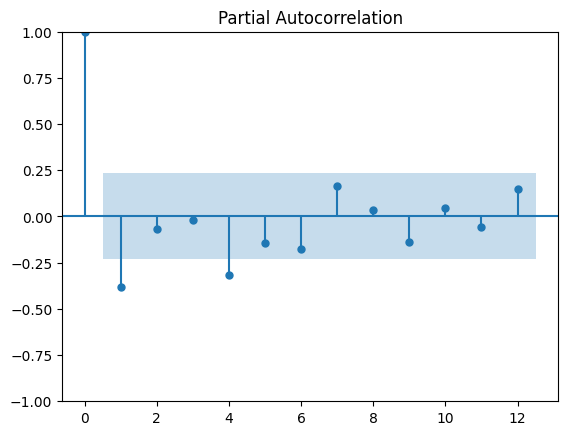

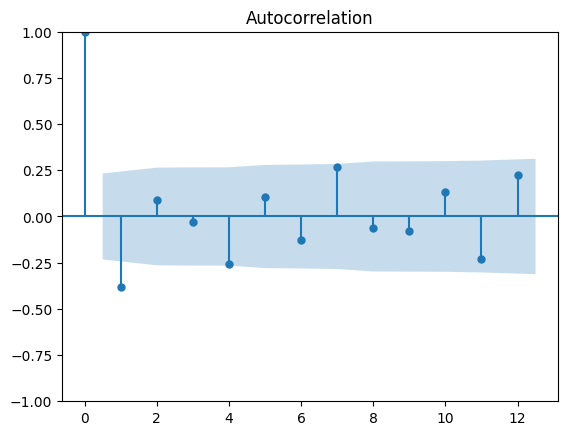

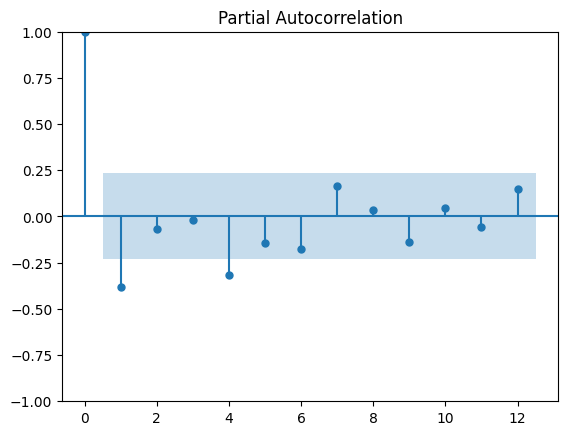

In [33]:
# 2. Make it stationary, then read the ACF/PACF of the STATIONARY series
stationary = train.diff().diff(4).dropna()                    # first difference + seasonal difference

pval_jj_diff2 = adfuller(stationary, result_object=True)[1]

print(f"ADF p-value: {pval_jj_diff2:.10f}")


if (pval_jj_diff2 <= 0.05):
    print(f"ADF Test: the Logged and Double-Differenced J&J data is Stationary!")
else:
    print(f"ADF Test: the Logged and Double-Differenced J&J data is non-Stationary!")


plot_acf(stationary, lags=12); plot_pacf(stationary, lags=12)

In [34]:
# 3. Grid search p and q by AIC (training data only)
jjresults = []
# jjd = 1
jjd_array = range(3)
jjp_array = range(3)
jjq_array = range(3)

for jjp, jjd, jjq in product(jjp_array, jjd_array, jjq_array):
    modelresult = ARIMA(train, order=(jjp, jjd, jjq), seasonal_order=(0, 1, 0, 4)).fit()
    jjresults.append((jjp, jjd, jjq, modelresult.aic))


C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\CharleyHanania\AppD

In [35]:

df_jjres = pd.DataFrame(jjresults, columns=['p', 'd', 'q', 'aic'])
df_jjres.sort_values('aic', ascending=True).head(100)

jjbest_p, jjbest_d, jjbest_q, jjbest_aic = df_jjres.sort_values('aic').iloc[0][['p', 'd', 'q', 'aic']]

best = df_jjres.sort_values('aic').iloc[0][['p', 'd', 'q', 'aic']]

# Remember:
# * p is the order of the autoregressive (AR) term,
# * d is the number of differences needed to make the series stationary, and
# * q is the order of the moving average (MA) term.
# This means that the model will use 1 lagged value of the time series as predictors,
# apply 1 difference to the series to remove trend,
# and use 1 lagged forecast error as predictor in the moving average component.


# print(f"Order of the autoregressive (AR) term: {jjbest_p}\nNumber of differences needed to make the series stationary: {jjbest_d}\nOrder of the moving average (MA) term: {jjbest_q}\naic value: {jjbest_aic}")

df_rows, df_cols = df_jjres.shape
df_jjres.sort_values('aic').head(df_rows)

,p,d,q,aic
13,1,1,1,-125.354373
19,2,0,1,-124.799072
22,2,1,1,-124.633808
4,0,1,1,-124.529854
5,0,1,2,-124.403345
10,1,0,1,-124.273552
11,1,0,2,-123.958218
14,1,1,2,-123.819354
23,2,1,2,-122.867394
18,2,0,0,-121.573859


In [36]:
# 4. Check residuals, then forecast the test period and compare MAE
fit = ARIMA(train, order=(jjbest_p, jjbest_d, jjbest_q), seasonal_order=(0, 1, 0, 4)).fit()
print('Ljung-Box p-value (lag 8):', round(acorr_ljungbox(fit.resid[5:], lags=[8])['lb_pvalue'].iloc[0], 3))

forecast = np.exp(fit.forecast(8)).values
print('MAE ARIMA:', round(mae(forecast), 3))
# Output: MAE naive 4.882 | seasonal naive 2.543 | ADF p-value 0.0
#         best by AIC ((1, 1, 1), -125.4) | Ljung-Box p 0.223 | MAE ARIMA 0.669

Ljung-Box p-value (lag 8): 0.224
MAE ARIMA: 0.669


In [37]:
fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                            value   No. Observations:                   76
Model:             ARIMA(1, 1, 1)x(0, 1, [], 4)   Log Likelihood                  65.677
Date:                          Sun, 25 Oct 2026   AIC                           -125.354
Time:                                  23:01:55   BIC                           -118.566
Sample:                              01-01-1960   HQIC                          -122.655
                                   - 10-01-1978                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2809      0.151      1.858      0.063      -0.015       0.577
ma.L1         -0.8978      0.083    -10.826      0.000      -1.060      -0.735
sigma2         0.0091      0.002      5.255      0.000       0.006       0.012
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 1.18
Prob(Q):                              0.98   Prob(JB):                         0.56
Heteroskedasticity (H):               0.52   Skew:                             0.18
Prob(H) (two-sided):                  0.12   Kurtosis:                         2.48
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

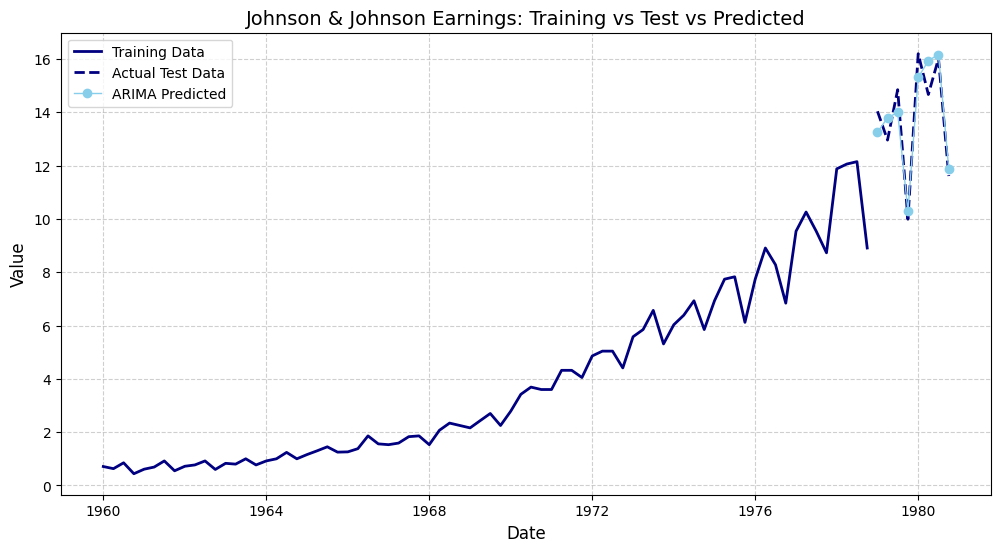

In [ ]:
# 5. Generate forecasts on the original scale
# Forecast 8 steps ahead (the size of our test set)
forecast_log = fit.forecast(steps=8)
forecast_original = np.exp(forecast_log)

# Create the evaluation plot
plt.figure(figsize=(12, 6))

# Plot historical training data (converted back from log scale)
plt.plot(train.index, np.exp(train), label="Training Data", color="navy", linewidth=2)

# Plot actual test data held out
plt.plot(test.index, np.exp(test), label="Actual Test Data", color="navy", linewidth=2, linestyle="--")

# Plot our ARIMA model predictions
plt.plot(test.index, forecast_original, label="ARIMA Predicted", color="skyblue", marker="o", linewidth=1)

# Graph styling details
plt.title("Johnson & Johnson Earnings: Training vs Test vs Predicted", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Value", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

**Reading the results:** both naïve baselines are beaten easily

* The differenced series is *stationary* (ADF p ≈ 0)
* AIC chooses ***ARIMA(1, 1, 1)*** with a seasonal difference
* The **Ljung–Box test** *p-value* of 0.22 (> 0.05) means **no significant pattern is left** in the residuals, *which is what we want*
* **ARIMA's MAE** (0.67) is about **a quarter** of the seasonal naïve's (2.54).

**NOTE:** statsmodels may print a convergence warning for some grid combinations; that's common and safe move on.
